# Кросс-валидация, порог и проверка во времени

Продолжение `Credit_Card_Fraud_Detection.ipynb`. Данные, признаки и модель те же. Здесь проверяю три вещи, которых не было в основном ноутбуке. Какой разброс у метрик, если считать не на одном разбиении. Какой порог выгоднее, если посчитать ошибки в деньгах. И как модель работает на более поздних транзакциях.

In [1]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score, confusion_matrix
from xgboost import XGBClassifier

if os.path.exists('creditcard.csv'):
    data = pd.read_csv('creditcard.csv')
else:
    with zipfile.ZipFile('creditcard.csv.zip') as z:
        data = pd.read_csv(z.open('creditcard.csv'))

# признаки как в основном ноутбуке
data['Hour'] = (data['Time'] % 86400) // 3600
data['Amount_log'] = np.log1p(data['Amount'])
data['V17_V14'] = data['V17'] * data['V14']
data['V12_V17'] = data['V12'] * data['V17']
data = data.drop_duplicates().reset_index(drop=True)

# та же модель, что в основном ноутбуке
def make_model():
    return XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.1,
                         scale_pos_weight=500, eval_metric='aucpr',
                         random_state=42, n_jobs=-1)

def metrics(y, proba, thr):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return dict(precision=precision_score(y, pred), recall=recall_score(y, pred),
                f1=f1_score(y, pred), pr_auc=average_precision_score(y, proba),
                tp=tp, fp=fp, fn=fn)

print(data.shape, data['Class'].sum())  # после удаления дублей 473 фрода

(283726, 35) 473


## Кросс-валидация

Разбиение 80/20 то же, что в основном ноутбуке. Тест не трогаю, на train делаю 5 фолдов со стратификацией.

In [2]:
X = data.drop(columns='Class')
y = data['Class']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
rows = []
oof = np.zeros(len(y_train))  # предсказания на фолдах, пригодятся для порога
for k, (tr, va) in enumerate(skf.split(X_train, y_train), 1):
    m = make_model().fit(X_train.iloc[tr], y_train.iloc[tr])
    p = m.predict_proba(X_train.iloc[va])[:, 1]
    oof[va] = p
    rows.append({'fold': k, **metrics(y_train.iloc[va], p, 0.5)})

cv = pd.DataFrame(rows).set_index('fold')
display(cv.round(3))
cv[['precision', 'recall', 'f1', 'pr_auc']].agg(['mean', 'std']).round(3)

,precision,recall,f1,pr_auc,tp,fp,fn
fold,,,,,,,
1,0.952,0.800,0.870,0.839,60,3,15
2,0.887,0.840,0.863,0.868,63,8,12
3,0.879,0.763,0.817,0.792,58,8,18
4,0.833,0.855,0.844,0.855,65,13,11
5,0.857,0.868,0.863,0.864,66,11,10


,precision,recall,f1,pr_auc
mean,0.882,0.825,0.851,0.844
std,0.045,0.043,0.021,0.031


**Вывод**
- Precision 0.88 ± 0.05, Recall 0.83 ± 0.04, PR-AUC 0.84 ± 0.03.
- На тесте было 0.88 / 0.80 / 0.81, это в пределах разброса. Тест не случайно удачный.

## Порог по стоимости ошибок

Пропущенный фрод стоит суммы операции (`Amount`). Ложное срабатывание стоит фиксированно `C_FP`, это звонок клиенту и ручная проверка. Сколько это реально, не знаю, поэтому беру 10 € и смотрю, что будет при других значениях.

Порог подбираю на предсказаниях с фолдов, на тесте проверяю один раз.

In [3]:
amount_train = X_train['Amount'].values
y_tr = y_train.values
thresholds = np.round(np.arange(0.01, 1.0, 0.01), 2)

def total_cost(y, proba, amount, thr, c_fp):
    pred = proba >= thr
    fn_cost = amount[(y == 1) & ~pred].sum()   # пропущенный фрод
    fp_cost = c_fp * ((y == 0) & pred).sum()   # ложные срабатывания
    return fn_cost + fp_cost

sens = []
for c_fp in [2, 5, 10, 25, 50]:
    costs = [total_cost(y_tr, oof, amount_train, t, c_fp) for t in thresholds]
    sens.append({'C_FP': c_fp, 'лучший порог': thresholds[int(np.argmin(costs))],
                 'стоимость при 0.5': round(total_cost(y_tr, oof, amount_train, 0.5, c_fp)),
                 'стоимость при лучшем': round(min(costs))})
pd.DataFrame(sens)

,C_FP,лучший порог,стоимость при 0.5,стоимость при лучшем
0,2,0.06,11028,10067
1,5,0.06,11157,10673
2,10,0.76,11372,11257
3,25,0.76,12017,11722
4,50,0.92,13092,12274


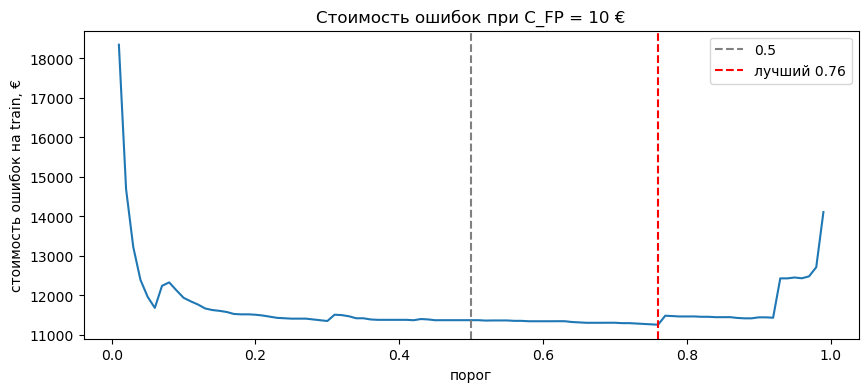

np.float64(0.76)

In [4]:
C_FP = 10
costs = [total_cost(y_tr, oof, amount_train, t, C_FP) for t in thresholds]
best_thr = thresholds[int(np.argmin(costs))]

plt.figure(figsize=(10, 4))
plt.plot(thresholds, costs)
plt.axvline(0.5, ls='--', c='grey', label='0.5')
plt.axvline(best_thr, ls='--', c='red', label=f'лучший {best_thr}')
plt.xlabel('порог'); plt.ylabel('стоимость ошибок на train, €')
plt.title(f'Стоимость ошибок при C_FP = {C_FP} €'); plt.legend(); plt.show()
best_thr

In [5]:
# обучаю на всём train, порог беру с фолдов
model = make_model().fit(X_train, y_train)
proba_test = model.predict_proba(X_test)[:, 1]
amount_test = X_test['Amount'].values

res = []
for name, thr in [('0.5', 0.5), (str(best_thr), best_thr)]:
    m = metrics(y_test, proba_test, thr)
    m['стоимость, €'] = round(total_cost(y_test.values, proba_test, amount_test, thr, C_FP))
    m['пропущено фрода, €'] = round(amount_test[(y_test.values == 1) & (proba_test < thr)].sum())
    res.append({'порог': name, **m})
pd.DataFrame(res).set_index('порог').round(3)

,precision,recall,f1,pr_auc,tp,fp,fn,"стоимость, €","пропущено фрода, €"
порог,,,,,,,,,
0.5,0.884,0.800,0.840,0.812,76,10,19,3885,3785
0.76,0.948,0.768,0.849,0.812,73,4,22,3852,3812


In [6]:
# какие операции пропущены при пороге 0.5
miss = X_test.assign(score=proba_test, y=y_test.values).query('y == 1 and score < 0.5')
print('пропущено', len(miss), 'операций на', round(miss['Amount'].sum()), '€')
display(miss.sort_values('Amount', ascending=False)[['Amount', 'score', 'Hour']].head(10).round(3))
print('доля потерь в 3 самых крупных', round(miss['Amount'].nlargest(3).sum() / miss['Amount'].sum(), 2))

пропущено 19 операций на 3785 €


,Amount,score,Hour
248322,1096.99,0.000,18.0
194676,723.21,0.026,12.0
100242,549.06,0.000,18.0
67805,519.90,0.000,14.0
145246,451.27,0.184,0.0
101128,320.00,0.001,18.0
52289,105.99,0.001,12.0
231118,8.00,0.002,16.0
228883,2.22,0.101,16.0
72475,1.79,0.000,15.0


доля потерь в 3 самых крупных 0.63


**Вывод**
- При 10 € лучший порог 0.76. Ложных срабатываний 4 вместо 10, но потери почти те же, 3 852 € против 3 885 €.
- Деньги уходят на пропущенный фрод, 19 операций на 3 785 €. Три самые крупные дают 63% потерь, скор у них около нуля. Такие операции модель не видит, порогом их не поймать.
- Кривая плоская, поэтому лучший порог прыгает. При 2–5 € он 0.06, при 10–25 € уже 0.76.

## Проверка во времени

При случайном разбиении в train попадают операции, которые были позже тестовых. В проде так не бывает. Беру первые 80% транзакций по `Time` в train и последние 20% в test. `Time` из признаков убираю, на более поздних данных его значения выходят за диапазон train.

In [7]:
d = data.sort_values('Time').reset_index(drop=True)
cut = int(len(d) * 0.8)
Xt = d.drop(columns=['Class', 'Time'])
yt = d['Class']
Xt_tr, Xt_te, yt_tr, yt_te = Xt.iloc[:cut], Xt.iloc[cut:], yt.iloc[:cut], yt.iloc[cut:]
print('train до', d['Time'].iloc[cut - 1], 'с; фрода в train', yt_tr.sum(), ', в test', yt_te.sum())

m_time = make_model().fit(Xt_tr, yt_tr)
p_time = m_time.predict_proba(Xt_te)[:, 1]

# для честного сравнения случайное разбиение тоже без Time
m_rand = make_model().fit(X_train.drop(columns='Time'), y_train)
p_rand = m_rand.predict_proba(X_test.drop(columns='Time'))[:, 1]

pd.DataFrame([
    {'разбиение': 'случайное, без Time', **metrics(y_test, p_rand, 0.5)},
    {'разбиение': 'по времени, без Time', **metrics(yt_te, p_time, 0.5)},
]).set_index('разбиение').round(3)

train до 145233.0 с; фрода в train 399 , в test 74


,precision,recall,f1,pr_auc,tp,fp,fn
разбиение,,,,,,,
"случайное, без Time",0.890,0.768,0.825,0.805,73,9,22
"по времени, без Time",0.824,0.757,0.789,0.793,56,12,18


**Вывод**
- По времени Precision упал с 0.89 до 0.82, Recall почти не изменился (0.77 и 0.76), PR-AUC 0.81 и 0.79.
- Фрода в таком тесте всего 74, часть разницы может быть шумом.
- Со `Time` на случайном разбиении Recall 0.80, без него 0.77. Похоже, модель частично запоминает время внутри двух дней, на новых данных это не поможет.

## Итоговые выводы

| Что проверял | Что получилось |
|---|---|
| Разброс метрик | PR-AUC 0.84 ± 0.03 на 5 фолдах, тест в пределах разброса |
| Порог по стоимости | 0.76 вместо 0.5, ложных 4 вместо 10, потери почти те же |
| Пропущенный фрод | 3 крупные операции дают 63% потерь, скор около нуля |
| Разбиение по времени | Precision 0.89 → 0.82 |
| Признак `Time` | Лучше не брать, модель запоминает время выгрузки |

### Ограничения
- Данные за 2 дня, неизвестно, насколько паттерны стабильны.
- V-признаки анонимизированы, не понять, чем пропущенные операции отличаются от пойманных.
- Цена ложного срабатывания условная.